# FinMark Milestone 2: Extended Analysis and Data Visualization

This notebook revisits the finalized Milestone 1 cleaned datasets and uses NumPy, Matplotlib, and Seaborn to examine distributions, categorical balance, relationships, time trends, and unusual observations. The findings support future customer segmentation, feature selection, and predictive modeling for FinMark analysts and decision-makers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

segments = pd.read_csv(
    "Cleaned_Customer_Demographics.csv",
    dtype={"CustomerID": "string"},
    parse_dates=["SignupDate"],
)
transactions = pd.read_csv(
    "Cleaned_Customer_Transactions.csv",
    dtype={"CustomerID": "string", "TransactionID": "string"},
    parse_dates=["TransactionDate"],
)
social = pd.read_csv(
    "Cleaned_Social_Media_Interactions.csv",
    dtype={"CustomerID": "string", "InteractionID": "string"},
    parse_dates=["InteractionDate"],
)

dataset_overview = pd.DataFrame({
    "Rows": [len(segments), len(transactions), len(social)],
    "Columns": [segments.shape[1], transactions.shape[1], social.shape[1]],
    "Duplicate IDs": [
        segments["CustomerID"].duplicated().sum(),
        transactions["TransactionID"].duplicated().sum(),
        social["InteractionID"].duplicated().sum(),
    ],
}, index=["Customer Demographics", "Transactions", "Social Interactions"])
display(dataset_overview)

,Rows,Columns,Duplicate IDs
Customer Demographics,3000,6,0
Transactions,3000,11,0
Social Interactions,3000,6,0


## Extended Numerical Analysis

The following NumPy calculations extend the Milestone 1 descriptive analysis with quartiles, IQR, range, coefficient of variation, and explicit valid-observation counts. Missing numeric amounts associated with unresolved `"Free"` labels are excluded from amount calculations.

In [2]:
def extended_statistics(values):
    values = pd.Series(values).dropna().to_numpy(dtype=float)
    q1, q3 = np.percentile(values, [25, 75])
    mean = np.mean(values)
    modes = pd.Series(values).mode().tolist()
    return {
        "Valid observations": len(values),
        "Mean": mean,
        "Median": np.median(values),
        "Mode": ", ".join(f"{mode:.2f}" for mode in modes),
        "Std. Dev.": np.std(values, ddof=1),
        "Variance": np.var(values, ddof=1),
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "Range": np.ptp(values),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "Coefficient of Variation (%)": np.std(values, ddof=1) / mean * 100,
    }

numerical_summary = pd.DataFrame({
    "Customer Age": extended_statistics(segments["Age"]),
    "Transaction Amount": extended_statistics(transactions["Amount"]),
}).T
display(numerical_summary)

,Valid observations,Mean,Median,Mode,Std. Dev.,Variance,Minimum,Maximum,Range,Q1,Q3,IQR,Coefficient of Variation (%)
Customer Age,3000,44.679667,45.0,45.00,14.437054,208.428529,18.0,70.0,52.0,34.0,57.0,23.0,32.312358
Transaction Amount,2971,491.930703,497.49,497.49,283.658418,80462.097901,-100.0,999.86,1099.86,253.25,724.225,470.975,57.662271


### Interpretation: Numerical Summary

- Customer age is centered near 45 years; its mean, median, and mode are nearly identical, indicating little overall skew. The mode also reflects the earlier median imputation, so a future model should retain an age-missingness indicator.
- Transaction amount has a much wider spread than age. The signed minimum of -100 is retained because it may represent a refund, reversal, or adjustment rather than an error.
- Amount statistics use 2,971 valid numeric records. The 29 unresolved `"Free"` labels are retained as transactions but excluded from numerical amount calculations pending a business rule.
- Scaling may benefit distance-based models because age and amount operate on substantially different ranges.

In [3]:
def frequency_table(series):
    counts = series.value_counts(dropna=False)
    return pd.DataFrame({
        "Count": counts,
        "Percent": (counts / len(series) * 100).round(2),
    })

for title, series in {
    "Income Level": segments["IncomeLevel"],
    "Product Category": transactions["ProductCategory"],
    "Payment Method": transactions["PaymentMethod"],
    "Social Platform": social["Platform"],
    "Sentiment": social["Sentiment"],
}.items():
    print(f"\n{title}")
    display(frequency_table(series))


Income Level


,Count,Percent
IncomeLevel,,
High,935,31.17
Low,918,30.60
Medium,863,28.77
Unknown,284,9.47



Product Category


,Count,Percent
ProductCategory,,
Clothing,568,18.93
Electronics,561,18.70
Automotive,538,17.93
Home & Garden,529,17.63
Health & Beauty,524,17.47
Unknown,280,9.33



Payment Method


,Count,Percent
PaymentMethod,,
Debit Card,762,25.4
Credit Card,753,25.1
PayPal,747,24.9
Bank Transfer,738,24.6



Social Platform


,Count,Percent
Platform,,
Instagram,916,30.53
Twitter,907,30.23
Facebook,887,29.57
Unknown,290,9.67



Sentiment


,Count,Percent
Sentiment,,
Positive,898,29.93
Neutral,870,29.00
Negative,861,28.70
Unknown,308,10.27
Very Negative,32,1.07
Very Positive,31,1.03


### Interpretation: Categorical Balance

- The main income, product, payment, and platform categories should be compared by both count and percentage so class size is not mistaken for importance.
- `Unknown` remains separate from observed categories because it represents missing information, not a genuine behavioral level.
- Extreme sentiment classes are much less common than the major sentiment classes. If sentiment becomes a prediction target, stratified splitting and class weights should be considered.
- Categorical predictors will require encoding, while high-cardinality identifiers such as `CustomerID` should be used for joins and data splitting rather than as direct model inputs.

In [4]:
def iqr_outlier_summary(series):
    values = pd.Series(series).dropna()
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((values < lower_bound) | (values > upper_bound)).sum()
    return {
        "Valid observations": len(values),
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "IQR outliers": int(outlier_count),
    }

outlier_summary = pd.DataFrame({
    "Customer Age": iqr_outlier_summary(segments["Age"]),
    "Transaction Amount": iqr_outlier_summary(transactions["Amount"]),
}).T
display(outlier_summary.round(2))

amount_state_summary = pd.Series({
    "Genuine numeric zero": int((transactions["Amount"] == 0).sum()),
    "Unresolved Free label": int(transactions["IsFreeLabel"].sum()),
    "Signed negative amount": int(transactions["IsNegativeAmount"].sum()),
    "Median-imputed source missing": int(transactions["WasAmountImputed"].sum()),
}, name="Transactions")
display(amount_state_summary.to_frame())

,Valid observations,Lower bound,Upper bound,IQR outliers
Customer Age,3000.0,-0.50,91.50,0.0
Transaction Amount,2971.0,-453.21,1430.69,0.0


,Transactions
Genuine numeric zero,29
Unresolved Free label,29
Signed negative amount,34
Median-imputed source missing,282


### Interpretation: Anomalies and Amount States

- The IQR rule is a screening method, not an automatic deletion rule. Values outside its bounds would require contextual review before removal.
- Genuine zeros, unresolved `"Free"` labels, signed negatives, and median-imputed amounts are counted separately because they represent different transaction states.
- Negative amounts require confirmation from FinMark stakeholders before deciding whether they belong in gross-spend, net-spend, or refund-specific features.
- Sensitivity analysis should compare model behavior with and without unresolved or imputed amount records.

In [5]:
transaction_demographics = transactions.merge(
    segments[["CustomerID", "Age", "IncomeLevel"]],
    on="CustomerID",
    how="inner",
)
transaction_demographics["AgeGroup"] = pd.cut(
    transaction_demographics["Age"],
    bins=[17, 25, 40, 60, 100],
    labels=["Youth", "Young Adult", "Adult", "Senior"],
)

print("Transaction amount by income level")
display(transaction_demographics.groupby("IncomeLevel")["Amount"].agg(["count", "mean", "median"]).round(2))
print("Transaction amount by age group")
display(transaction_demographics.groupby("AgeGroup", observed=False)["Amount"].agg(["count", "mean", "median"]).round(2))

transaction_features = transactions.groupby("CustomerID").agg(
    TotalSpend=("Amount", "sum"),
    AverageAmount=("Amount", "mean"),
    TransactionCount=("TransactionID", "count"),
).reset_index()
social_features = social.groupby("CustomerID").agg(
    SocialInteractions=("InteractionID", "count"),
).reset_index()

customer_features = (
    segments[["CustomerID", "Age", "IncomeLevel"]]
    .merge(transaction_features, on="CustomerID", how="left")
    .merge(social_features, on="CustomerID", how="left")
)
customer_features[["TotalSpend", "TransactionCount", "SocialInteractions"]] = (
    customer_features[["TotalSpend", "TransactionCount", "SocialInteractions"]].fillna(0)
)

correlation_columns = ["Age", "TotalSpend", "AverageAmount", "TransactionCount", "SocialInteractions"]
correlation_matrix = customer_features[correlation_columns].corr()
display(correlation_matrix.round(3))

Transaction amount by income level


,count,mean,median
IncomeLevel,,,
High,940,492.59,497.49
Low,890,497.38,497.49
Medium,877,486.88,497.49
Unknown,264,487.97,497.49


Transaction amount by age group


,count,mean,median
AgeGroup,,,
Youth,387,473.71,497.49
Young Adult,712,482.14,497.49
Adult,1356,494.87,497.49
Senior,516,511.37,497.49


,Age,TotalSpend,AverageAmount,TransactionCount,SocialInteractions
Age,1.000,-0.002,0.041,-0.020,0.010
TotalSpend,-0.002,1.000,0.606,0.863,-0.007
AverageAmount,0.041,0.606,1.000,-0.003,0.010
TransactionCount,-0.020,0.863,-0.003,1.000,-0.011
SocialInteractions,0.010,-0.007,0.010,-0.011,1.000


### Interpretation: Cross-Dataset Relationships

- Transactions are joined to demographics by `CustomerID`, while customer-level transaction and social features are aggregated before merging. This avoids treating unrelated row positions as matched observations.
- Income-level and age-group summaries are descriptive comparisons; observed differences do not establish that age or income causes spending behavior.
- `TotalSpend`, `AverageAmount`, and `TransactionCount` are mathematically related, so using all of them in a linear model may introduce multicollinearity.
- Near-zero correlations do not prove that a feature has no predictive value; nonlinear patterns and interactions should be evaluated during modeling.

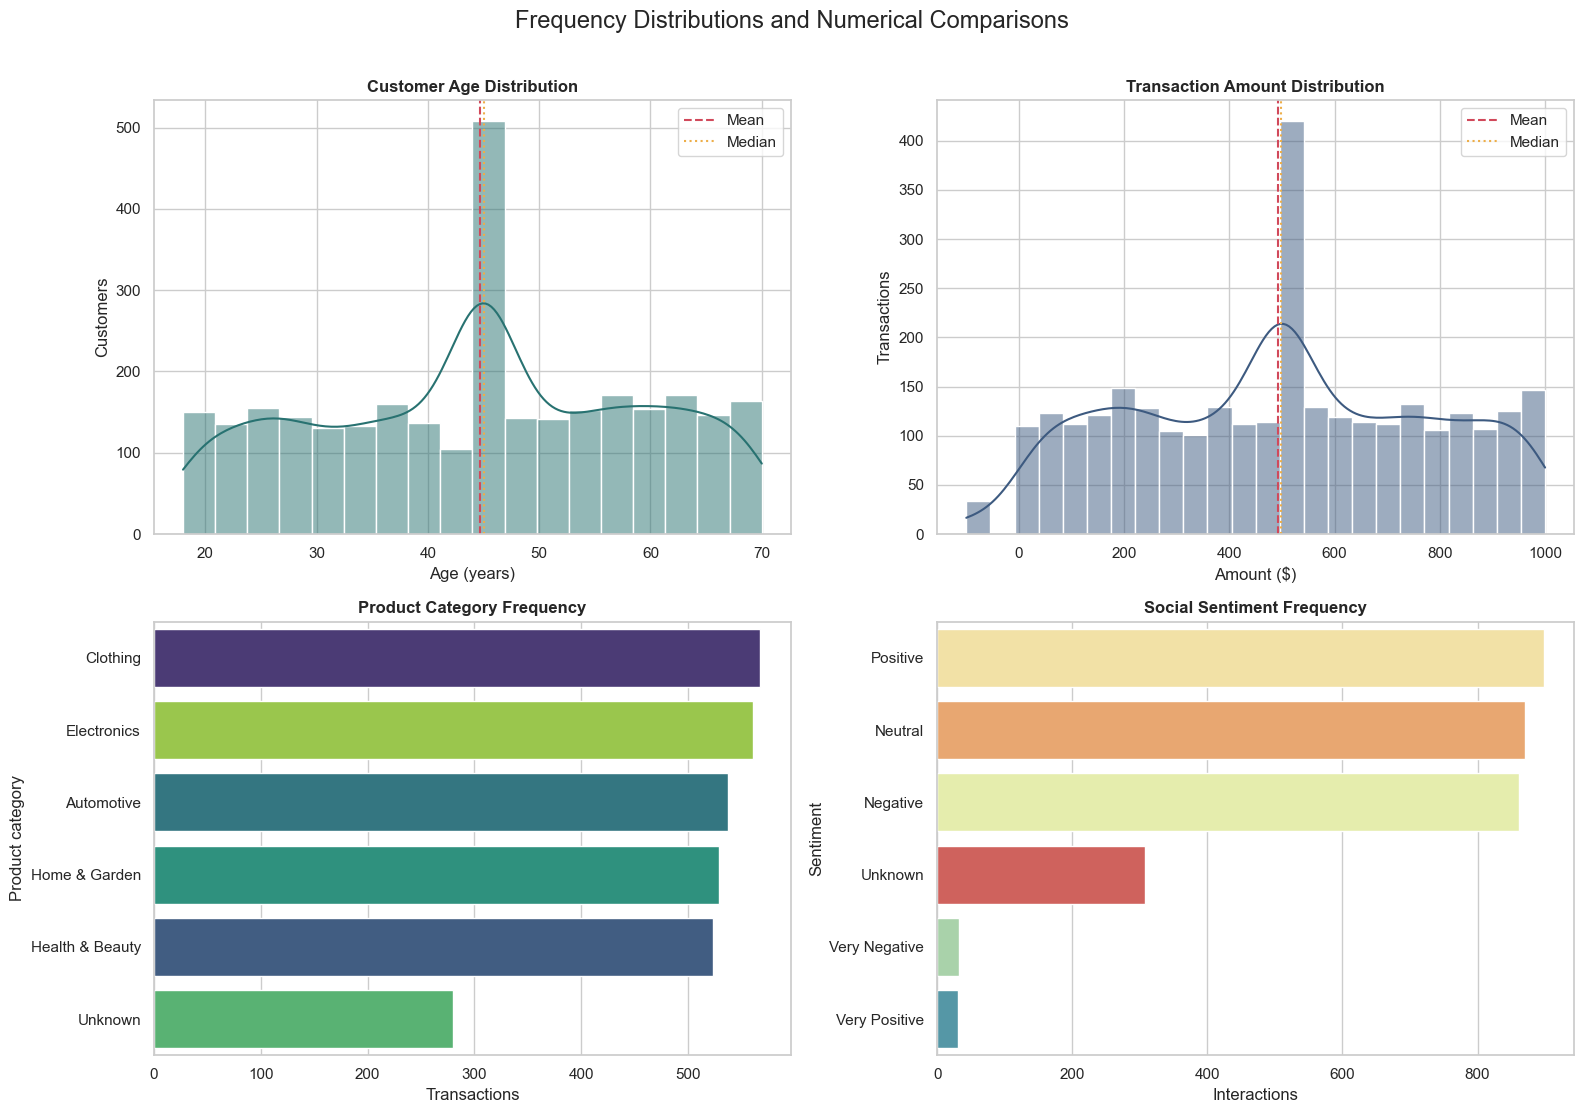

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.histplot(segments, x="Age", bins=18, kde=True, color="#287271", ax=axes[0, 0])
axes[0, 0].axvline(segments["Age"].mean(), color="#D1495B", linestyle="--", label="Mean")
axes[0, 0].axvline(segments["Age"].median(), color="#EDAE49", linestyle=":", label="Median")
axes[0, 0].set(title="Customer Age Distribution", xlabel="Age (years)", ylabel="Customers")
axes[0, 0].legend()

sns.histplot(transactions, x="Amount", bins=24, kde=True, color="#3D5A80", ax=axes[0, 1])
axes[0, 1].axvline(transactions["Amount"].mean(), color="#D1495B", linestyle="--", label="Mean")
axes[0, 1].axvline(transactions["Amount"].median(), color="#EDAE49", linestyle=":", label="Median")
axes[0, 1].set(title="Transaction Amount Distribution", xlabel="Amount ($)", ylabel="Transactions")
axes[0, 1].legend()

product_order = transactions["ProductCategory"].value_counts().index
sns.countplot(data=transactions, y="ProductCategory", order=product_order, hue="ProductCategory", palette="viridis", legend=False, ax=axes[1, 0])
axes[1, 0].set(title="Product Category Frequency", xlabel="Transactions", ylabel="Product category")

sentiment_order = social["Sentiment"].value_counts().index
sns.countplot(data=social, y="Sentiment", order=sentiment_order, hue="Sentiment", palette="Spectral", legend=False, ax=axes[1, 1])
axes[1, 1].set(title="Social Sentiment Frequency", xlabel="Interactions", ylabel="Sentiment")

fig.suptitle("Frequency Distributions and Numerical Comparisons", fontsize=17, y=1.01)
plt.tight_layout()
plt.show()

### Interpretation: Distributions and Dominant Categories

- The age histogram is broadly centered, while the amount histogram shows much greater dispersion. Mean and median reference lines make skew and central concentration easier to compare.
- A central spike can reflect median imputation rather than a naturally frequent amount or age; this should be considered during feature engineering.
- Product categories are comparatively balanced, reducing immediate concern that one category dominates transaction-based learning.
- The sentiment count plot makes the rare extreme classes and the sizable `Unknown` class visible. `Unknown` should not be silently merged with Neutral.

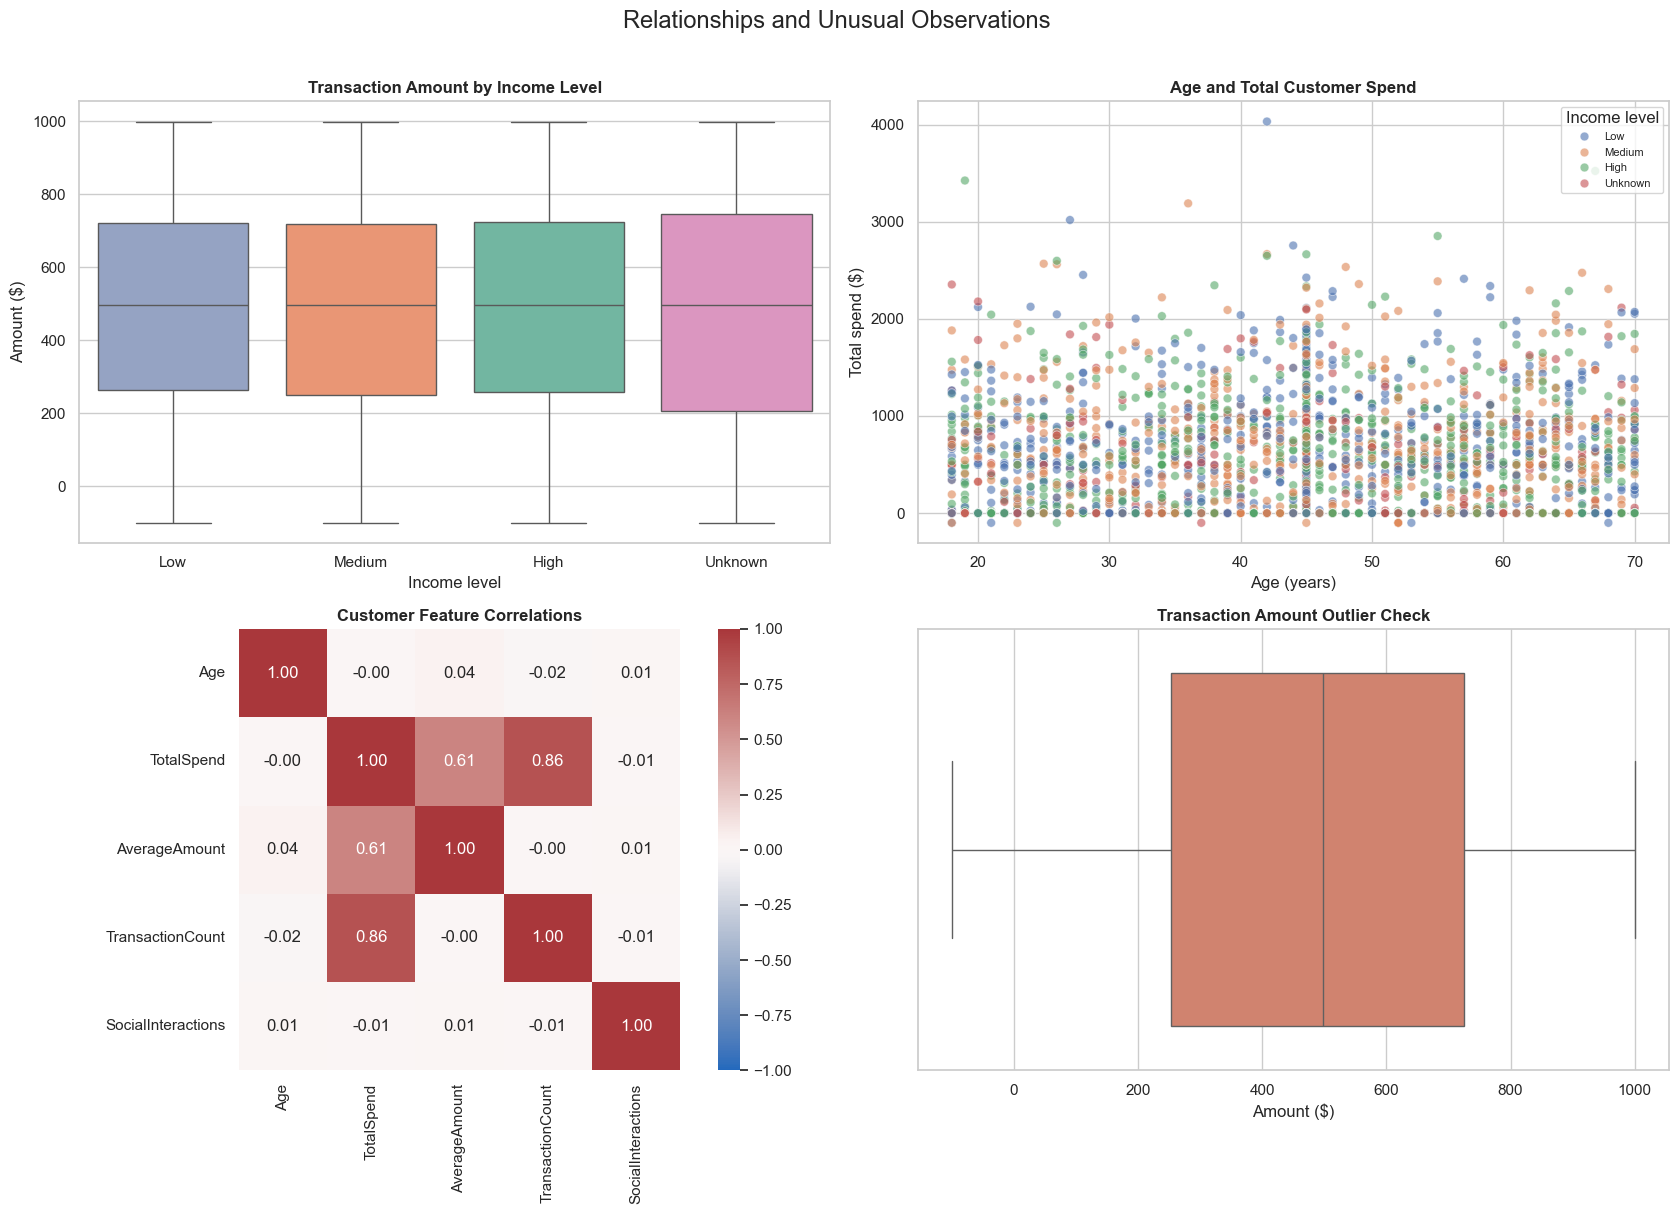

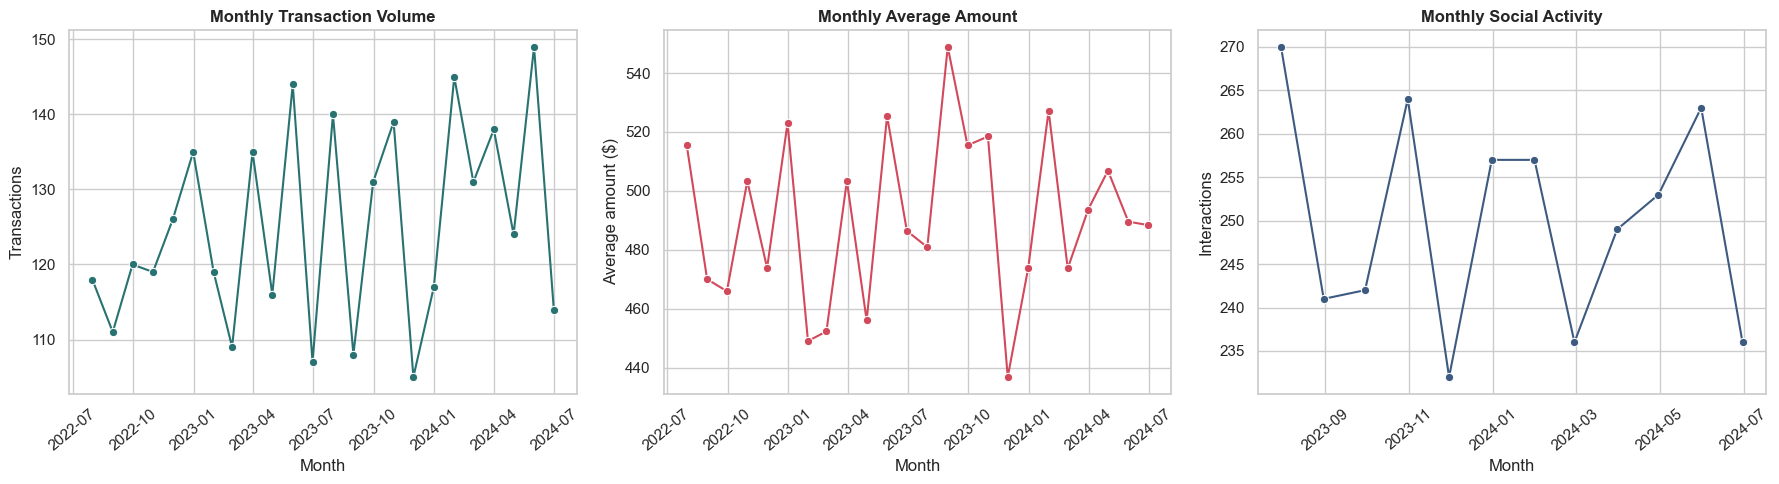

Peak transaction volume: May 2024
Highest monthly average amount: August 2023
Peak social activity: July 2023


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(17, 12))

income_order = ["Low", "Medium", "High", "Unknown"]
sns.boxplot(data=transaction_demographics, x="IncomeLevel", y="Amount", order=income_order, hue="IncomeLevel", palette="Set2", legend=False, ax=axes[0, 0])
axes[0, 0].set(title="Transaction Amount by Income Level", xlabel="Income level", ylabel="Amount ($)")

sns.scatterplot(data=customer_features, x="Age", y="TotalSpend", hue="IncomeLevel", hue_order=income_order, alpha=0.6, s=40, ax=axes[0, 1])
axes[0, 1].set(title="Age and Total Customer Spend", xlabel="Age (years)", ylabel="Total spend ($)")
axes[0, 1].legend(title="Income level", fontsize=8)

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=axes[1, 0])
axes[1, 0].set_title("Customer Feature Correlations")

sns.boxplot(x=transactions["Amount"], color="#E07A5F", ax=axes[1, 1])
axes[1, 1].set(title="Transaction Amount Outlier Check", xlabel="Amount ($)")

fig.suptitle("Relationships and Unusual Observations", fontsize=17, y=1.01)
plt.tight_layout()
plt.show()

monthly_transactions = (
    transactions.set_index("TransactionDate")
    .resample("ME")
    .agg(TransactionCount=("TransactionID", "count"), AverageAmount=("Amount", "mean"))
)
monthly_social = (
    social.set_index("InteractionDate")
    .resample("ME")
    .agg(InteractionCount=("InteractionID", "count"))
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.lineplot(data=monthly_transactions, x=monthly_transactions.index, y="TransactionCount", marker="o", color="#287271", ax=axes[0])
axes[0].set(title="Monthly Transaction Volume", xlabel="Month", ylabel="Transactions")
sns.lineplot(data=monthly_transactions, x=monthly_transactions.index, y="AverageAmount", marker="o", color="#D1495B", ax=axes[1])
axes[1].set(title="Monthly Average Amount", xlabel="Month", ylabel="Average amount ($)")
sns.lineplot(data=monthly_social, x=monthly_social.index, y="InteractionCount", marker="o", color="#3D5A80", ax=axes[2])
axes[2].set(title="Monthly Social Activity", xlabel="Month", ylabel="Interactions")
for axis in axes:
    axis.tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

print(f"Peak transaction volume: {monthly_transactions['TransactionCount'].idxmax():%B %Y}")
print(f"Highest monthly average amount: {monthly_transactions['AverageAmount'].idxmax():%B %Y}")
print(f"Peak social activity: {monthly_social['InteractionCount'].idxmax():%B %Y}")

### Interpretation and Modeling Recommendations

- Income-level box plots permit comparison of centers and spread, but overlapping distributions should be interpreted cautiously and tested statistically before drawing stronger conclusions.
- The scatter plot and heatmap summarize linear relationships. Engineered behavioral features may be more useful for segmentation than raw identifiers, but correlated spending features should be screened for redundancy.
- Monthly lines show variation over time, not proven seasonality; the available time span is too short for a strong seasonal claim.
- Time-based prediction should use chronological validation to prevent leakage. Customer-level prediction should split by `CustomerID` so one customer's records do not appear in both training and testing sets.
- Before modeling, FinMark should confirm the meanings of negative and `"Free"` transactions, retain missingness/review flags, encode categorical variables, scale numerical features when appropriate, and address rare sentiment classes.